# Elektrodinamika Kabel Koaksial: Model Lengkap Empat Lapisan Silindris

**Mata Kuliah: Elektrodinamika Klasik**  
**Program Studi: Magister Fisika, Universitas Padjadjaran**  
**Acuan Teori: David J. Griffiths, *Introduction to Electrodynamics*, Edisi ke-4 (Bab 2, 5, dan 8)**

---

## 1. Deskripsi Geometri Kabel Koaksial Empat Lapisan

Kabel koaksial nyata tersusun atas empat zona material konsentris yang terpusat pada sumbu simetri $z$ dalam koordinat silinder $(r, \phi, z)$. Model empat lapisan ini meliputi:

1. **Konduktor Dalam (Silinder Pejal Logam, $0 \le r \le a$):**  
   Memiliki jari-jari penampang $a$, terbuat dari konduktor bermutu tinggi (misalnya tembaga). Mengalirkan arus total $I_1$ ke arah aksial $+z$. Dengan asumsi arus terdistribusi seragam melintasi penampang $\pi a^2$, rapat arus volume konduktor dalam dinyatakan oleh:
   $$\mathbf{J}_1 = \frac{I_1}{\pi a^2}\,\hat{\mathbf{z}},\qquad (r \le a)$$

2. **Isolator Dalam / Dielektrik ($a < r \le b$):**  
   Lapisan dielektrik berpenampang anular dengan jari-jari dalam $a$ dan jari-jari luar $b$. Lapisan ini berfungsi mencegah hubungan singkat antara konduktor dalam dan konduktor luar serta menampung medan listrik tegangan tinggi. Di wilayah ini tidak terdapat pembawa muatan bebas, sehingga:
   $$\mathbf{J} = \mathbf{0},\qquad (a < r \le b)$$

3. **Konduktor Luar (Selongsong Anular Silindris, $b < r \le c$):**  
   Lapisan konduktor pelindung (shielding) berupa cangkang silinder berketebalan berhingga $(c - b)$ dengan luas penampang melintang $\pi(c^2 - b^2)$. Lapisan ini mengalirkan arus total $I_2$. Sesuai instruksi gambar acuan perkuliahan:
   $$\text{"Kerjakan hal yang sama, namun arus } I_1 \text{ dan } I_2 \text{ searah."}$$
   Maka arus $I_2$ juga diarahkan ke $+z$ dengan rapat arus volume seragam:
   $$\mathbf{J}_2 = \frac{I_2}{\pi(c^2 - b^2)}\,\hat{\mathbf{z}},\qquad (b < r \le c)$$

4. **Isolator Luar / Jaket Pelindung ($c < r \le d$):**  
   Lapisan polimer terluar (misalnya PVC atau polietilena) berjejari dalam $c$ dan jejari luar $d$ yang melindungi kabel dari kerusakan mekanis dan korosi lingkungan:
   $$\mathbf{J} = \mathbf{0},\qquad (c < r \le d)$$

5. **Ruang Bebas Luar ($r > d$):**  
   Medium luar kabel (udara atau ruang hampa) dengan rapat arus $\mathbf{J} = \mathbf{0}$.

Target matematis kajian ini adalah menurunkan distribusi medan magnet $\mathbf{B}(r)$ pada kelima daerah menggunakan Hukum Ampère, mengkaji medan listrik $\mathbf{E}(r)$ melalui Hukum Gauss, serta memvisualisasikan seluruh sistem dalam proyeksi 3D Three.js yang parameternya dapat divariasikan secara kontinu.


In [5]:
import json
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import HTML, display
from html import escape

# Tetapan fundamental elektrostatika dan magnetostatika (SI)
mu_0 = 4 * np.pi * 1e-7      # Permeabilitas vakum [H/m atau N/A^2]
epsilon_0 = 8.8541878128e-12 # Permitivitas vakum [F/m]
c = 1.0 / np.sqrt(mu_0 * epsilon_0) # Laju gelombang elektromagnetik dalam vakum [m/s]

print(f"Permeabilitas Vakum (mu_0)    : {mu_0:.6e} H/m")
print(f"Permitivitas Vakum (eps_0)    : {epsilon_0:.6e} F/m")
print(f"Laju Gelombang EM (c)         : {c:.6e} m/s")


Permeabilitas Vakum (mu_0)    : 1.256637e-06 H/m
Permitivitas Vakum (eps_0)    : 8.854188e-12 F/m
Laju Gelombang EM (c)         : 2.997925e+08 m/s


## 2. Penurunan Medan Magnet $\mathbf{B}(\mathbf{r})$ Menggunakan Hukum Ampère

Berdasarkan simetri silinder tak berhingga, medan magnet hanya memiliki komponen azimutal:
$$\mathbf{B}(\mathbf{r}) = B_\phi(r)\,\hat{\boldsymbol{\phi}}$$

Dengan memilih loop Amperian berupa lingkaran berjejari $r$ pada penampang melintang tegak lurus sumbu kabel, ruas kiri sirkulasi medan adalah:
$$\oint_C \mathbf{B} \cdot d\mathbf{l} = \int_0^{2\pi} B_\phi(r)\,(r\,d\phi) = 2\pi r\,B_\phi(r)$$

Ruas kanan dihitung berdasarkan total arus terlingkupi $I_{\text{enc}}(r) = \int_{\mathcal{S}} \mathbf{J} \cdot d\mathbf{A}$.

---

### Daerah 1: $r \le a$ (Di Dalam Konduktor Dalam)
Loop Amperian berada di dalam konduktor dalam. Arus yang dilingkupi adalah:
$$I_{\text{enc}} = J_1 (\pi r^2) = \left( \frac{I_1}{\pi a^2} \right) \pi r^2 = I_1 \frac{r^2}{a^2}$$

Substitusi ke dalam Hukum Ampère:
$$2\pi r\,B_\phi(r) = \mu_0 I_1 \frac{r^2}{a^2} \implies B_\phi(r) = \frac{\mu_0 I_1 r}{2\pi a^2}$$
Medan magnet bernilai nol di sumbu kabel ($r = 0$), bertambah secara linear terhadap $r$, dan mencapai nilai $B_\phi(a) = \frac{\mu_0 I_1}{2\pi a}$ pada permukaan $r = a$.

---

### Daerah 2: $a < r \le b$ (Di Dalam Isolator Dalam / Dielektrik)
Loop Amperian melingkupi seluruh arus dari konduktor dalam, sementara konduktor luar belum terlingkupi:
$$I_{\text{enc}} = I_1$$

Maka:
$$2\pi r\,B_\phi(r) = \mu_0 I_1 \implies B_\phi(r) = \frac{\mu_0 I_1}{2\pi r}$$
Medan meluruh secara hiperbolik sebanding dengan $1/r$. Pada batas $r = a$, medan bernilai tepat sama dengan batas dalam: $B_\phi(a^+) = B_\phi(a^-)$, membuktikan kontinuitas medan.

---

### Daerah 3: $b < r \le c$ (Di Dalam Konduktor Luar Berketebalan Hingga)
Loop Amperian melingkupi seluruh arus $I_1$ dan sebagian arus $I_2$ dari lapisan konduktor luar seluas $\pi(r^2 - b^2)$:
$$I_{\text{enc}}(r) = I_1 + J_2 \pi(r^2 - b^2) = I_1 + I_2 \frac{r^2 - b^2}{c^2 - b^2}$$

Substitusi ke dalam Hukum Ampère:
$$2\pi r\,B_\phi(r) = \mu_0 \left( I_1 + I_2 \frac{r^2 - b^2}{c^2 - b^2} \right)$$
$$B_\phi(r) = \frac{\mu_0}{2\pi r}\left( I_1 + I_2 \frac{r^2 - b^2}{c^2 - b^2} \right)$$

Uji kontinuitas pada kedua batas konduktor luar:
- Pada $r = b$: $B_\phi(b) = \frac{\mu_0 I_1}{2\pi b}$ (kontinu dengan daerah isolator dalam).
- Pada $r = c$: $B_\phi(c) = \frac{\mu_0 (I_1 + I_2)}{2\pi c}$ (kontinu dengan daerah luar).
Karena arus terdistribusi secara volume, tidak terdapat lompatan diskontinuitas medan magnetik di seluruh antarmuka.

---

### Daerah 4: $c < r \le d$ (Di Dalam Isolator Luar / Jaket Pelindung)
Loop Amperian melingkupi seluruh arus dari konduktor dalam dan konduktor luar:
$$I_{\text{enc}} = I_1 + I_2$$
$$B_\phi(r) = \frac{\mu_0 (I_1 + I_2)}{2\pi r}$$

---

### Daerah 5: $r > d$ (Di Luar Kabel)
Arus total terlingkupi tetap sama dengan daerah 4:
$$I_{\text{enc}} = I_1 + I_2$$
$$B_\phi(r) = \frac{\mu_0 (I_1 + I_2)}{2\pi r}$$

---

### Analisis Komparatif: Arus Searah vs Arus Berlawanan
Jika konduktor luar difungsikan sebagai arus balik seperti pada transmisi koaksial standar ($I_2 = -I_1$):
- Pada daerah 3 ($b < r \le c$): $B_\phi(r) = \frac{\mu_0 I_1}{2\pi r}\left(\frac{c^2 - r^2}{c^2 - b^2}\right)$, yang meluruh mulus hingga tepat bernilai nol pada $r = c$.
- Pada daerah 4 dan 5 ($r \ge c$): $I_{\text{enc}} = I_1 + (-I_1) = 0 \implies B_\phi(r) = 0$.
Hal ini membuktikan fungsi penting konduktor luar dalam mengurung seluruh medan magnet di dalam kabel dan mencegah kebocoran interferensi ke jaket isolator luar maupun ke ruang sekitar.


In [6]:
# Verifikasi Simbolik Menggunakan SymPy untuk Model 4 Lapisan
r, a, b, c_rad, d_rad = sp.symbols('r a b c d', positive=True)
I_1, I_2, mu0 = sp.symbols('I_1 I_2 mu_0', positive=True)

# Formula B_phi pada kelima daerah
B_1 = (mu0 * I_1 * r) / (2 * sp.pi * a**2)
B_2 = (mu0 * I_1) / (2 * sp.pi * r)
B_3 = (mu0 / (2 * sp.pi * r)) * (I_1 + I_2 * (r**2 - b**2) / (c_rad**2 - b**2))
B_4 = (mu0 * (I_1 + I_2)) / (2 * sp.pi * r)
B_5 = B_4

# 1. Pengecekan Kontinuitas di Setiap Antarmuka
kontinuitas_a = sp.simplify(B_2.subs(r, a) - B_1.subs(r, a))
kontinuitas_b = sp.simplify(B_3.subs(r, b) - B_2.subs(r, b))
kontinuitas_c = sp.simplify(B_4.subs(r, c_rad) - B_3.subs(r, c_rad))
kontinuitas_d = sp.simplify(B_5.subs(r, d_rad) - B_4.subs(r, d_rad))

# 2. Pengecekan Curl B = mu_0 * J (Hukum Ampere Diferensial)
# (curl B)_z = (1/r) * d/dr (r * B_phi)
curl_1 = sp.simplify((1/r) * sp.diff(r * B_1, r))
curl_2 = sp.simplify((1/r) * sp.diff(r * B_2, r))
curl_3 = sp.simplify((1/r) * sp.diff(r * B_3, r))
curl_4 = sp.simplify((1/r) * sp.diff(r * B_4, r))

J_1 = I_1 / (sp.pi * a**2)
J_2 = I_2 / (sp.pi * (c_rad**2 - b**2))

print("=== HASIL VALIDASI KONTINUITAS MEDAN B(r) ===")
print(f"Selisih di r = a : {kontinuitas_a}  (Kontinu sempurna)")
print(f"Selisih di r = b : {kontinuitas_b}  (Kontinu sempurna)")
print(f"Selisih di r = c : {kontinuitas_c}  (Kontinu sempurna)")
print(f"Selisih di r = d : {kontinuitas_d}  (Kontinu sempurna)")

print("\n=== HASIL VALIDASI BENTUK DIFERENSIAL (del x B = mu_0 * J) ===")
print(f"Daerah 1 (r <= a)     : curl B = {curl_1} == mu_0 * J_1 -> {sp.simplify(curl_1 - mu0*J_1) == 0}")
print(f"Daerah 2 (a < r <= b) : curl B = {curl_2} (Sesuai J = 0 pada isolator dalam)")
print(f"Daerah 3 (b < r <= c) : curl B = {curl_3} == mu_0 * J_2 -> {sp.simplify(curl_3 - mu0*J_2) == 0}")
print(f"Daerah 4 (c < r <= d) : curl B = {curl_4} (Sesuai J = 0 pada jaket pelindung)")


=== HASIL VALIDASI KONTINUITAS MEDAN B(r) ===
Selisih di r = a : 0  (Kontinu sempurna)
Selisih di r = b : 0  (Kontinu sempurna)
Selisih di r = c : 0  (Kontinu sempurna)
Selisih di r = d : 0  (Kontinu sempurna)

=== HASIL VALIDASI BENTUK DIFERENSIAL (del x B = mu_0 * J) ===
Daerah 1 (r <= a)     : curl B = I_1*mu_0/(pi*a**2) == mu_0 * J_1 -> True
Daerah 2 (a < r <= b) : curl B = 0 (Sesuai J = 0 pada isolator dalam)
Daerah 3 (b < r <= c) : curl B = -I_2*mu_0/(pi*(b**2 - c**2)) == mu_0 * J_2 -> True
Daerah 4 (c < r <= d) : curl B = 0 (Sesuai J = 0 pada jaket pelindung)


## 3. Distribusi Medan Listrik $\mathbf{E}(\mathbf{r})$ dan Vektor Poynting $\mathbf{S}$

Kabel koaksial mentransmisikan daya melalui interaksi antara tegangan listrik $V$ antar-konduktor dan arus listrik $I_1$.

### 3.1 Medan Listrik $\mathbf{E}(r)$ Berdasarkan Hukum Gauss
Jika konduktor dalam membawa rapat muatan linear $+\lambda$ dan konduktor luar membawa $-\lambda$:
$$\oint_{\mathcal{S}} \mathbf{E} \cdot d\mathbf{A} = \frac{Q_{\text{enc}}}{\varepsilon}$$

1. **Di dalam Konduktor Dalam ($r < a$):**  
   Sebagai konduktor logam dalam keadaan elektrostatik, medan listrik bernilai nol:
   $$\mathbf{E}(r) = \mathbf{0}$$

2. **Di dalam Isolator Dalam / Dielektrik ($a < r < b$):**  
   Permukaan Gauss silinder berjejari $r$ melingkupi muatan linear $+\lambda$:
   $$2\pi r L E_r(r) = \frac{\lambda L}{\varepsilon_1} \implies \mathbf{E}(r) = \frac{\lambda}{2\pi \varepsilon_1 r}\,\hat{\mathbf{r}}$$
   Dengan menghitung beda potensial $V = -\int_b^a E_r\,dr = \frac{\lambda}{2\pi \varepsilon_1}\ln(b/a)$, medan listrik dinyatakan dalam fungsi tegangan $V$:
   $$\mathbf{E}(r) = \frac{V}{r\ln(b/a)}\,\hat{\mathbf{r}},\qquad (a < r < b)$$

3. **Di dalam Konduktor Luar ($b < r < c$):**  
   Di dalam material logam pelindung, medan elektrostatik ideal adalah nol:
   $$\mathbf{E}(r) = \mathbf{0}$$

4. **Di dalam Isolator Luar dan Ruang Luar ($r > c$):**  
   Karena konduktor luar menginduksi muatan total $-\lambda$, muatan netto terlingkupi sama dengan nol:
   $$Q_{\text{enc}} = +\lambda - \lambda = 0 \implies \mathbf{E}(r) = \mathbf{0},\qquad (r > c)$$

---

### 3.2 Aliran Daya Elektrodinamika (Vektor Poynting)
Vektor Poynting mengukur kerapatan fluks daya yang merambat melintasi ruang:
$$\mathbf{S} = \frac{1}{\mu_0}(\mathbf{E} \times \mathbf{B})$$

Pada ruang isolator dalam ($a < r < b$):
$$\mathbf{S}(r) = \frac{1}{\mu_0}\left[ \frac{V}{r\ln(b/a)}\,\hat{\mathbf{r}} \right] \times \left[ \frac{\mu_0 I_1}{2\pi r}\,\hat{\boldsymbol{\phi}} \right] = \frac{V I_1}{2\pi \ln(b/a)\,r^2}\,\hat{\mathbf{z}}$$

Daya total yang mengalir melintasi penampang anular kabel adalah:
$$P = \int_a^b \mathbf{S} \cdot d\mathbf{A} = \int_a^b \frac{V I_1}{2\pi \ln(b/a)\,r^2} (2\pi r\,dr) = \frac{V I_1}{\ln(b/a)} \int_a^b \frac{dr}{r} = V I_1$$

Di dalam konduktor dalam, konduktor luar, maupun jaket pelindung luar, medan listrik radial bernilai nol, sehingga $\mathbf{S} = \mathbf{0}$. Hal ini membuktikan bahwa transmisi energi elektromagnetik terpusat murni di dalam lapisan isolator dalam (dielektrik) di antara kedua konduktor.


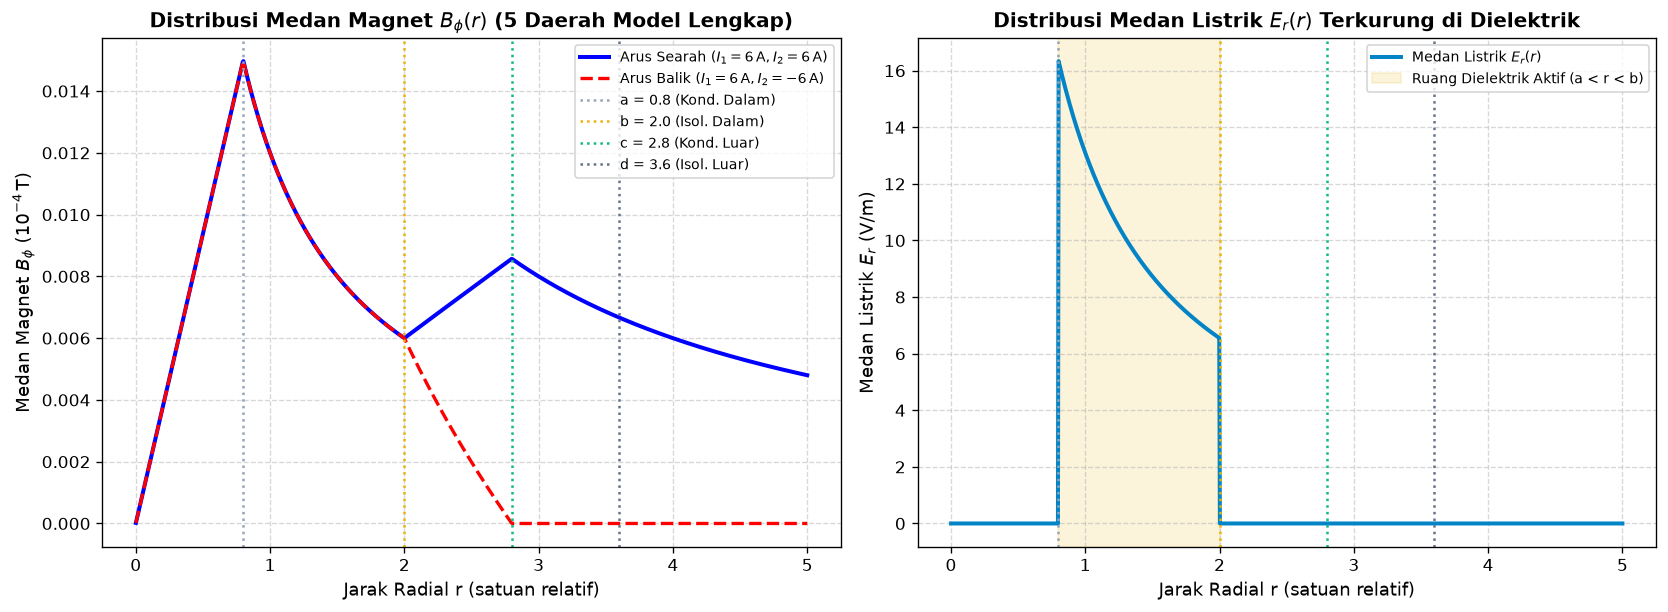

In [7]:
# Plot Komparasi Analitis Distribusi Medan B(r) dan E(r) pada Model 4 Lapisan
def hitung_medan_4lapisan(r_arr, a, b, c_rad, d_rad, I1, I2, V0):
    B_arr = np.zeros_like(r_arr)
    E_arr = np.zeros_like(r_arr)
    
    for idx, r_val in enumerate(r_arr):
        # 1. Konduktor dalam (r <= a)
        if r_val <= a:
            B_arr[idx] = (mu_0 * I1 * r_val) / (2 * np.pi * a**2)
            E_arr[idx] = 0.0
        # 2. Isolator dalam / dielektrik (a < r <= b)
        elif r_val <= b:
            B_arr[idx] = (mu_0 * I1) / (2 * np.pi * r_val)
            E_arr[idx] = V0 / (r_val * np.log(b / a))
        # 3. Konduktor luar (b < r <= c)
        elif r_val <= c_rad:
            B_arr[idx] = (mu_0 / (2 * np.pi * r_val)) * (I1 + I2 * (r_val**2 - b**2) / (c_rad**2 - b**2))
            E_arr[idx] = 0.0
        # 4. Isolator luar / jaket pelindung (c < r <= d)
        elif r_val <= d_rad:
            B_arr[idx] = (mu_0 * (I1 + I2)) / (2 * np.pi * r_val)
            E_arr[idx] = 0.0
        # 5. Luar kabel (r > d)
        else:
            B_arr[idx] = (mu_0 * (I1 + I2)) / (2 * np.pi * r_val)
            E_arr[idx] = 0.0
            
    return B_arr, E_arr

# Parameter Geometri (skala mm atau cm relatif)
a_val = 0.8
b_val = 2.0
c_val = 2.8
d_val = 3.6
I1_val = 6.0 # Ampere
I2_val = 6.0 # Ampere (Searah)
V_val = 12.0 # Volt

r_grid = np.linspace(0.001, 5.0, 1000)

B_searah, E_prof = hitung_medan_4lapisan(r_grid, a_val, b_val, c_val, d_val, I1_val, I2_val, V_val)
B_balik, _ = hitung_medan_4lapisan(r_grid, a_val, b_val, c_val, d_val, I1_val, -I1_val, V_val)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=120)

# Subplot 1: Medan Magnetik B_phi(r)
ax1.plot(r_grid, B_searah * 1e4, 'b-', lw=2.4, label=r'Arus Searah ($I_1 = 6\,\mathrm{A}, I_2 = 6\,\mathrm{A}$)')
ax1.plot(r_grid, B_balik * 1e4, 'r--', lw=2.0, label=r'Arus Balik ($I_1 = 6\,\mathrm{A}, I_2 = -6\,\mathrm{A}$)')

# Batas Lapisan
ax1.axvline(a_val, color='#94a3b8', ls=':', lw=1.5, label=f'a = {a_val} (Kond. Dalam)')
ax1.axvline(b_val, color='#eab308', ls=':', lw=1.5, label=f'b = {b_val} (Isol. Dalam)')
ax1.axvline(c_val, color='#10b981', ls=':', lw=1.5, label=f'c = {c_val} (Kond. Luar)')
ax1.axvline(d_val, color='#64748b', ls=':', lw=1.5, label=f'd = {d_val} (Isol. Luar)')

ax1.set_xlabel('Jarak Radial r (satuan relatif)', fontsize=11)
ax1.set_ylabel(r'Medan Magnet $B_\phi$ ($10^{-4}\,\mathrm{T}$)', fontsize=11)
ax1.set_title(r'Distribusi Medan Magnet $B_\phi(r)$ (5 Daerah Model Lengkap)', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', frameon=True, fontsize=8.5)

# Subplot 2: Medan Listrik E_r(r)
ax2.plot(r_grid, E_prof, color='#0284c7', lw=2.4, label=r'Medan Listrik $E_r(r)$')
ax2.axvline(a_val, color='#94a3b8', ls=':', lw=1.5)
ax2.axvline(b_val, color='#eab308', ls=':', lw=1.5)
ax2.axvline(c_val, color='#10b981', ls=':', lw=1.5)
ax2.axvline(d_val, color='#64748b', ls=':', lw=1.5)

# Arsiran Daerah Isolator Dalam
ax2.axvspan(a_val, b_val, color='#eab308', alpha=0.15, label='Ruang Dielektrik Aktif (a < r < b)')

ax2.set_xlabel('Jarak Radial r (satuan relatif)', fontsize=11)
ax2.set_ylabel(r'Medan Listrik $E_r$ (V/m)', fontsize=11)
ax2.set_title(r'Distribusi Medan Listrik $E_r(r)$ Terkurung di Dielektrik', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()


## 4. Proyeksi Ruang 3D Interaktif Model Empat Lapisan Menggunakan Three.js

Aplikasi simulasi tiga dimensi berikut merekonstruksi kabel koaksial lengkap dengan empat lapisan material:
1. **Konduktor Dalam (Copper Core, $r \le a$):** dirender dengan material logam tembaga solid bertekstur logam.
2. **Isolator Dalam (Dielectric Core, $a < r \le b$):** material isolator dielektrik (putih gading transparan).
3. **Konduktor Luar (Metallic Braid Shield, $b < r \le c$):** selongsong logam perak pelindung dengan ketebalan fisik nyata.
4. **Isolator Luar (Outer PVC Jacket, $c < r \le d$):** jaket polimer pelindung terluar (gelap bertekstur matte).

**Fitur Kontrol:**
- Slider variabel independen $a, b, c, d$ yang secara otomatis menjaga relasi $a < b < c < d$.
- Slider arus $I_1$ dan $I_2$, dilengkapi tombol preset *Arus Searah* vs *Arus Balik*.
- Mode visualisasi medan: Medan Magnet $\mathbf{B}$, Medan Listrik $\mathbf{E}$, Aliran Poynting $\mathbf{S}$, atau Kombinasi Lengkap.
- Fitur *Stepped Cutaway 3D* (irisan penampang melintang dan memanjang bertingkat) yang menyingkap keempat lapisan silinder secara bersamaan.
- Panel grafik profil analitis real-time di sudut kanvas yang memperbarui grafik pada kelima daerah secara serentak.


In [8]:
# Render Simulasi Tiga Dimensi Interaktif Three.js (Model 4 Lapisan)
threejs_code = r"""<!DOCTYPE html>
<html lang="id">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0, maximum-scale=1.0, user-scalable=no">
  <title>Simulasi 3D Kabel Koaksial 4 Lapisan</title>
  <style>
    :root {
      --bg: #ffffff;
      --surface: rgba(255, 255, 255, 0.90);
      --border: rgba(226, 232, 240, 0.85);
      --text: #0f172a;
      --text-secondary: #475569;
      --text-muted: #64748b;
      --primary: #0284c7;
      
      --c-core: #d97706;       /* Tembaga */
      --c-diel: #eab308;       /* Dielektrik dalam */
      --c-shield: #0284c7;     /* Konduktor luar */
      --c-jacket: #475569;     /* Jaket pelindung luar */
      
      --shadow-sm: 0 2px 6px -1px rgba(15, 23, 42, 0.05);
      --shadow-md: 0 12px 28px -8px rgba(15, 23, 42, 0.08);
      --shadow-lg: 0 20px 40px -12px rgba(15, 23, 42, 0.12);
      --ease-spring: cubic-bezier(0.16, 1, 0.3, 1);
    }
    * {
      box-sizing: border-box;
      margin: 0;
      padding: 0;
      -webkit-tap-highlight-color: transparent;
    }
    html, body {
      width: 100%;
      height: 100%;
      overflow: hidden;
      font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif;
      background: var(--bg);
      color: var(--text);
    }
    #canvas-container {
      position: relative;
      width: 100%;
      height: 100%;
      overflow: hidden;
      display: flex;
    }
    #viewport {
      width: 100%;
      height: 100%;
      display: block;
      outline: none;
    }

    /* Floating Toolbar */
    .app-toolbar {
      position: absolute;
      top: 14px;
      left: 14px;
      right: 14px;
      display: flex;
      align-items: center;
      justify-content: space-between;
      gap: 10px;
      pointer-events: none;
      z-index: 40;
    }
    .toolbar-brand {
      pointer-events: auto;
      display: inline-flex;
      align-items: center;
      gap: 8px;
      padding: 7px 12px;
      background: var(--surface);
      backdrop-filter: blur(18px) saturate(180%);
      -webkit-backdrop-filter: blur(18px) saturate(180%);
      border: 1px solid var(--border);
      border-radius: 9999px;
      box-shadow: var(--shadow-sm);
    }
    .brand-pulse {
      width: 8px;
      height: 8px;
      border-radius: 50%;
      background: #10b981;
      box-shadow: 0 0 0 3px rgba(16, 185, 129, 0.2);
    }
    .brand-title {
      font-size: 12px;
      font-weight: 700;
      color: var(--text);
    }
    .brand-badge {
      font-size: 10px;
      font-weight: 600;
      color: var(--primary);
      background: rgba(2, 132, 199, 0.09);
      padding: 2px 7px;
      border-radius: 9999px;
    }
    .toolbar-actions {
      pointer-events: auto;
      display: inline-flex;
      align-items: center;
      gap: 6px;
      background: var(--surface);
      backdrop-filter: blur(18px) saturate(180%);
      padding: 4px;
      border: 1px solid var(--border);
      border-radius: 9999px;
      box-shadow: var(--shadow-sm);
    }
    .toolbar-btn {
      display: inline-flex;
      align-items: center;
      gap: 6px;
      height: 36px;
      min-width: 36px;
      padding: 0 12px;
      border-radius: 9999px;
      font-size: 12px;
      font-weight: 600;
      color: var(--text-secondary);
      background: transparent;
      border: 1px solid transparent;
      cursor: pointer;
      transition: all 0.2s;
    }
    .toolbar-btn.icon-only {
      padding: 0;
      width: 36px;
      justify-content: center;
    }
    .toolbar-btn:hover {
      color: var(--text);
      background: rgba(15, 23, 42, 0.04);
    }
    .toolbar-btn:active {
      transform: scale(0.96);
    }
    .toolbar-btn.active {
      background: var(--primary);
      color: #ffffff;
      box-shadow: 0 3px 10px -2px rgba(2, 132, 199, 0.4);
    }
    .toggle-pill {
      width: 6px;
      height: 6px;
      border-radius: 50%;
      background: #94a3b8;
    }
    .toolbar-btn.active .toggle-pill {
      background: rgba(255, 255, 255, 0.4);
    }

    /* Collapsible Drawers */
    .drawer {
      position: absolute;
      top: 66px;
      left: 14px;
      width: 330px;
      max-height: calc(100% - 80px);
      background: var(--surface);
      backdrop-filter: blur(20px) saturate(180%);
      -webkit-backdrop-filter: blur(20px) saturate(180%);
      border: 1px solid var(--border);
      border-radius: 16px;
      box-shadow: var(--shadow-lg);
      display: flex;
      flex-direction: column;
      z-index: 35;
      overflow: hidden;
      transition: transform 0.38s var(--ease-spring), opacity 0.25s, visibility 0.38s;
      transform: translateX(0);
      opacity: 1;
      visibility: visible;
    }
    .drawer.is-collapsed {
      transform: translateX(calc(-100% - 24px));
      opacity: 0;
      visibility: hidden;
      pointer-events: none;
    }
    .drawer-header {
      display: flex;
      align-items: center;
      justify-content: space-between;
      padding: 12px 16px;
      border-bottom: 1px solid rgba(226, 232, 240, 0.7);
      background: rgba(255, 255, 255, 0.4);
    }
    .drawer-title {
      font-size: 13px;
      font-weight: 700;
      color: var(--text);
    }
    .drawer-close-btn {
      display: flex;
      align-items: center;
      justify-content: center;
      width: 32px;
      height: 32px;
      border-radius: 8px;
      border: none;
      background: transparent;
      color: var(--text-muted);
      cursor: pointer;
      transition: all 0.15s;
    }
    .drawer-close-btn:hover {
      background: rgba(15, 23, 42, 0.06);
      color: var(--text);
    }
    .drawer-content {
      padding: 14px 16px;
      overflow-y: auto;
      flex: 1;
    }

    .section-label {
      font-size: 10px;
      font-weight: 700;
      text-transform: uppercase;
      letter-spacing: 0.08em;
      color: var(--text-muted);
      margin: 12px 0 6px;
      padding-bottom: 4px;
      border-bottom: 1px solid rgba(226, 232, 240, 0.7);
    }
    .section-label:first-child { margin-top: 0; }
    .control-group { margin-bottom: 10px; }
    .control-label {
      display: flex;
      justify-content: space-between;
      margin-bottom: 4px;
      font-size: 11.5px;
      color: var(--text-secondary);
      font-weight: 500;
    }
    .control-label span.val {
      color: var(--text);
      font-family: ui-monospace, SFMono-Regular, Menlo, Monaco, Consolas, monospace;
      font-weight: 700;
      background: rgba(15, 23, 42, 0.05);
      padding: 1px 6px;
      border-radius: 5px;
    }
    input[type=range] {
      width: 100%;
      height: 6px;
      accent-color: var(--primary);
      margin: 6px 0;
      cursor: pointer;
    }
    .select-mode {
      width: 100%;
      padding: 7px 10px;
      background: #f8fafc;
      border: 1px solid var(--border);
      border-radius: 8px;
      color: var(--text);
      font-size: 12px;
      margin-top: 3px;
      font-weight: 500;
      cursor: pointer;
    }
    .btn-row {
      display: flex;
      gap: 6px;
      margin-top: 6px;
    }
    .action-btn {
      flex: 1;
      min-height: 36px;
      padding: 6px 10px;
      background: rgba(2, 132, 199, 0.08);
      border: 1px solid rgba(2, 132, 199, 0.25);
      border-radius: 8px;
      color: var(--text);
      font-size: 11px;
      font-weight: 600;
      cursor: pointer;
      transition: all 0.18s;
    }
    .action-btn:hover {
      background: var(--primary);
      color: #fff;
    }
    .action-btn.active {
      background: var(--primary);
      color: #fff;
    }
    .checkbox-row {
      display: flex;
      align-items: center;
      gap: 10px;
      min-height: 38px;
      padding: 4px 6px;
      border-radius: 8px;
      cursor: pointer;
      font-size: 11.5px;
      color: var(--text-secondary);
      font-weight: 500;
    }
    .checkbox-row input {
      width: 17px;
      height: 17px;
      accent-color: var(--primary);
    }

    /* Graph Panel */
    .graph-panel {
      position: absolute;
      bottom: 14px;
      right: 14px;
      width: 320px;
      background: var(--surface);
      backdrop-filter: blur(20px) saturate(180%);
      -webkit-backdrop-filter: blur(20px) saturate(180%);
      border: 1px solid var(--border);
      border-radius: 16px;
      padding: 12px 14px;
      box-shadow: var(--shadow-lg);
      z-index: 35;
      transition: transform 0.38s var(--ease-spring), opacity 0.25s, visibility 0.38s;
      transform: translateY(0);
      opacity: 1;
      visibility: visible;
    }
    .graph-panel.is-collapsed {
      transform: translateY(calc(100% + 24px));
      opacity: 0;
      visibility: hidden;
      pointer-events: none;
    }
    .graph-header {
      display: flex;
      align-items: center;
      justify-content: space-between;
      margin-bottom: 8px;
    }
    .graph-header h3 {
      font-size: 11px;
      font-weight: 700;
      color: var(--primary);
      text-transform: uppercase;
      letter-spacing: 0.06em;
    }
    #plotCanvas {
      width: 100%;
      height: 125px;
      background: #f8fafc;
      border: 1px solid #e2e8f0;
      border-radius: 8px;
      display: block;
    }
    .legend-grid {
      display: grid;
      grid-template-columns: 1fr 1fr;
      gap: 5px;
      font-size: 10px;
      margin-top: 8px;
      color: var(--text-muted);
    }
    .legend-item {
      display: flex;
      align-items: center;
      gap: 5px;
    }
    .dot {
      width: 7px;
      height: 7px;
      border-radius: 50%;
    }

    /* Mobile Responsive */
    @media (max-width: 768px) {
      .brand-badge { display: none; }
      .toolbar-btn .btn-text { display: none; }
      .toolbar-btn { min-width: 42px; height: 42px; padding: 0 10px; }
      .drawer {
        top: auto;
        bottom: 0;
        left: 0;
        right: 0;
        width: 100%;
        max-height: 68vh;
        border-radius: 20px 20px 0 0;
        transform: translateY(0);
      }
      .drawer.is-collapsed { transform: translateY(105%); }
      .graph-panel {
        bottom: 0;
        right: 0;
        left: 0;
        width: 100%;
        border-radius: 18px 18px 0 0;
      }
    }
  </style>
  <script type="importmap">
    {
      "imports": {
        "three": "https://cdn.jsdelivr.net/npm/three@0.170.0/build/three.module.js",
        "three/addons/": "https://cdn.jsdelivr.net/npm/three@0.170.0/examples/jsm/"
      }
    }
  </script>
</head>
<body>
  <div id="canvas-container">
    <canvas id="viewport"></canvas>

    <!-- Top Navigation Toolbar -->
    <header class="app-toolbar" role="toolbar" aria-label="Toolbar Interaktif Simulasi">
      <div class="toolbar-brand">
        <div class="brand-pulse"></div>
        <span class="brand-title">Kabel Koaksial</span>
        <span class="brand-badge">Model 4 Lapisan</span>
      </div>

      <nav class="toolbar-actions">
        <button id="btn-toggle-config" class="toolbar-btn active" type="button" title="Buka / Tutup Konfigurasi">
          <svg width="15" height="15" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round">
            <line x1="4" y1="21" x2="4" y2="14"></line><line x1="4" y1="10" x2="4" y2="3"></line>
            <line x1="12" y1="21" x2="12" y2="12"></line><line x1="12" y1="8" x2="12" y2="3"></line>
            <line x1="20" y1="21" x2="20" y2="16"></line><line x1="20" y1="12" x2="20" y2="3"></line>
            <line x1="1" y1="14" x2="7" y2="14"></line><line x1="9" y1="8" x2="15" y2="8"></line><line x1="17" y1="16" x2="23" y2="16"></line>
          </svg>
          <span class="btn-text">Parameter</span>
          <span class="toggle-pill"></span>
        </button>

        <button id="btn-toggle-graph" class="toolbar-btn active" type="button" title="Buka / Tutup Grafik">
          <svg width="15" height="15" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round">
            <polyline points="22 12 18 12 15 21 9 3 6 12 2 12"></polyline>
          </svg>
          <span class="btn-text">Grafik</span>
          <span class="toggle-pill"></span>
        </button>

        <button id="btn-reset-view" class="toolbar-btn icon-only" type="button" title="Reset Sudut Pandang">
          <svg width="15" height="15" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round">
            <path d="M3 12a9 9 0 1 0 9-9 9.75 9.75 0 0 0-6.74 2.74L3 8"/>
            <path d="M3 3v5h5"/>
          </svg>
        </button>
      </nav>
    </header>

    <!-- Collapsible Config Drawer -->
    <aside id="config-drawer" class="drawer" aria-label="Panel Konfigurasi">
      <div class="drawer-header">
        <h2 class="drawer-title">🎛️ Parameter 4 Lapisan</h2>
        <button id="btn-close-config" class="drawer-close-btn" type="button" title="Tutup">✕</button>
      </div>

      <div class="drawer-content">
        <div class="section-label">Geometri Lapisan Silinder</div>

        <div class="control-group">
          <div class="control-label">
            <span>1. Konduktor Dalam (a)</span>
            <span class="val" id="val-a">0.70</span>
          </div>
          <input type="range" id="slider-a" min="0.3" max="1.3" step="0.05" value="0.70">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>2. Isolator Dalam (b)</span>
            <span class="val" id="val-b">1.70</span>
          </div>
          <input type="range" id="slider-b" min="1.0" max="2.6" step="0.05" value="1.70">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>3. Konduktor Luar (c)</span>
            <span class="val" id="val-c">2.40</span>
          </div>
          <input type="range" id="slider-c" min="1.8" max="3.4" step="0.05" value="2.40">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>4. Isolator Luar / Jaket (d)</span>
            <span class="val" id="val-d">3.10</span>
          </div>
          <input type="range" id="slider-d" min="2.6" max="4.2" step="0.05" value="3.10">
        </div>

        <div class="section-label">Arus Listrik Aksial</div>

        <div class="control-group">
          <div class="control-label">
            <span>Arus Inti I₁ (A)</span>
            <span class="val" id="val-I1">5.0</span>
          </div>
          <input type="range" id="slider-I1" min="-10" max="10" step="0.5" value="5.0">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>Arus Luar I₂ (A)</span>
            <span class="val" id="val-I2">5.0</span>
          </div>
          <input type="range" id="slider-I2" min="-10" max="10" step="0.5" value="5.0">
        </div>

        <div class="btn-row">
          <button id="btn-searah" class="action-btn active" type="button">Arus Searah (+I₁, +I₂)</button>
          <button id="btn-lawan" class="action-btn" type="button">Arus Balik (+I₁, −I₁)</button>
        </div>

        <div class="section-label">Tampilan Visualisasi</div>

        <div class="control-group">
          <select id="select-field" class="select-mode">
            <option value="B">Medan Magnet B (Azimutal φ)</option>
            <option value="E">Medan Listrik E (Radial r)</option>
            <option value="S">Vektor Poynting S (Aksial z)</option>
            <option value="ALL">Kombinasi Ortogonal (E, B, S)</option>
          </select>
        </div>

        <label class="checkbox-row">
          <input type="checkbox" id="chk-cutaway" checked>
          <span>Potongan Melintang Bertingkat (Cutaway)</span>
        </label>
      </div>
    </aside>

    <!-- Collapsible Graph Drawer -->
    <aside id="graph-drawer" class="graph-panel" aria-label="Panel Grafik">
      <div class="graph-header">
        <h3 id="graph-title">Distribusi Medan B(r) pada 5 Daerah</h3>
        <button id="btn-close-graph" class="drawer-close-btn" type="button" title="Tutup">✕</button>
      </div>
      <canvas id="plotCanvas" width="300" height="125"></canvas>
      <div class="legend-grid">
        <div class="legend-item"><span class="dot" style="background:#ea580c;"></span> r ≤ a (Inti)</div>
        <div class="legend-item"><span class="dot" style="background:#facc15;"></span> a < r ≤ b (Isol. Dalam)</div>
        <div class="legend-item"><span class="dot" style="background:#0284c7;"></span> b < r ≤ c (Kond. Luar)</div>
        <div class="legend-item"><span class="dot" style="background:#64748b;"></span> c < r ≤ d (Jaket Luar)</div>
      </div>
    </aside>
  </div>

  <script type="module">
    import * as THREE from 'three';
    import { OrbitControls } from 'three/addons/controls/OrbitControls.js';

    let state = {
      a: 0.70,
      b: 1.70,
      c: 2.40,
      d: 3.10,
      I1: 5.0,
      I2: 5.0,
      mode: 'B',
      cutaway: true,
      length: 6.2,
      isConfigOpen: true,
      isGraphOpen: true
    };

    const canvas = document.querySelector('#viewport');
    const renderer = new THREE.WebGLRenderer({ canvas, antialias: true, alpha: true });
    renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
    renderer.setSize(canvas.clientWidth, canvas.clientHeight, false);

    const scene = new THREE.Scene();
    scene.background = new THREE.Color(0xffffff);

    const camera = new THREE.PerspectiveCamera(45, canvas.clientWidth / canvas.clientHeight, 0.1, 100);
    camera.position.set(8.5, 6.5, 9.5);

    const controls = new OrbitControls(camera, renderer.domElement);
    controls.enableDamping = true;
    controls.dampingFactor = 0.05;
    controls.target.set(0, 0, 0);

    // Pencahayaan
    const ambientLight = new THREE.AmbientLight(0xffffff, 0.95);
    scene.add(ambientLight);
    const dirLight1 = new THREE.DirectionalLight(0xffffff, 1.2);
    dirLight1.position.set(10, 15, 12);
    scene.add(dirLight1);
    const dirLight2 = new THREE.DirectionalLight(0x0284c7, 0.4);
    dirLight2.position.set(-10, -5, -8);
    scene.add(dirLight2);

    const grid = new THREE.GridHelper(16, 32, 0x94a3b8, 0xe2e8f0);
    grid.position.y = -3.2;
    scene.add(grid);

    const cableGroup = new THREE.Group();
    const fieldGroup = new THREE.Group();
    scene.add(cableGroup);
    scene.add(fieldGroup);

    function buildCableMeshes() {
      while(cableGroup.children.length > 0) {
        const obj = cableGroup.children[0];
        if (obj.geometry) obj.geometry.dispose();
        if (obj.material) {
          if (Array.isArray(obj.material)) obj.material.forEach(m => m.dispose());
          else obj.material.dispose();
        }
        cableGroup.remove(obj);
      }

      const thetaLength = state.cutaway ? Math.PI * 1.5 : Math.PI * 2;
      const L = state.length;

      // 1. Lapisan 1: Konduktor Dalam (Copper Core, r <= a)
      const geom1 = new THREE.CylinderGeometry(state.a, state.a, L, 48, 1, false, 0, thetaLength);
      const mat1 = new THREE.MeshStandardMaterial({
        color: 0xd97706,
        roughness: 0.3,
        metalness: 0.85,
        side: THREE.DoubleSide
      });
      cableGroup.add(new THREE.Mesh(geom1, mat1));

      // 2. Lapisan 2: Isolator Dalam (a < r <= b)
      const geom2 = new THREE.CylinderGeometry(state.b, state.b, L, 48, 1, false, 0, thetaLength);
      const mat2 = new THREE.MeshPhysicalMaterial({
        color: 0xfef08a,
        transparent: true,
        opacity: 0.35,
        roughness: 0.25,
        transmission: 0.6,
        side: THREE.DoubleSide,
        depthWrite: false
      });
      cableGroup.add(new THREE.Mesh(geom2, mat2));

      // 3. Lapisan 3: Konduktor Luar (b < r <= c)
      const geom3 = new THREE.CylinderGeometry(state.c, state.c, L, 48, 1, false, 0, thetaLength);
      const mat3 = new THREE.MeshStandardMaterial({
        color: 0x0284c7,
        roughness: 0.35,
        metalness: 0.8,
        transparent: true,
        opacity: 0.55,
        side: THREE.DoubleSide
      });
      cableGroup.add(new THREE.Mesh(geom3, mat3));

      // 4. Lapisan 4: Jaket Pelindung (c < r <= d)
      const geom4 = new THREE.CylinderGeometry(state.d, state.d, L, 48, 1, true, 0, thetaLength);
      const mat4 = new THREE.MeshStandardMaterial({
        color: 0x475569,
        roughness: 0.6,
        metalness: 0.2,
        side: THREE.DoubleSide,
        transparent: true,
        opacity: 0.70
      });
      cableGroup.add(new THREE.Mesh(geom4, mat4));

      // Cutaway Faces
      if (state.cutaway) {
        const layers = [
          { r0: 0, r1: state.a, col: 0xb45309 },
          { r0: state.a, r1: state.b, col: 0xca8a04 },
          { r0: state.b, r1: state.c, col: 0x0284c7 },
          { r0: state.c, r1: state.d, col: 0x334155 }
        ];

        layers.forEach(ly => {
          const w = ly.r1 - ly.r0;
          const posMid = (ly.r0 + ly.r1) * 0.5;

          const planeGeom = new THREE.PlaneGeometry(w, L);
          const planeMat = new THREE.MeshStandardMaterial({ color: ly.col, side: THREE.DoubleSide, roughness: 0.5 });
          
          const p1 = new THREE.Mesh(planeGeom, planeMat);
          p1.position.set(posMid, 0, 0);
          p1.rotation.y = Math.PI / 2;
          cableGroup.add(p1);

          const p2 = new THREE.Mesh(planeGeom, planeMat);
          p2.position.set(0, 0, -posMid);
          cableGroup.add(p2);
        });
      }

      // Panah I1
      if (Math.abs(state.I1) > 0.1) {
        const dir1 = new THREE.Vector3(0, state.I1 > 0 ? 1 : -1, 0);
        const arrow1 = new THREE.ArrowHelper(dir1, new THREE.Vector3(0, -L*0.28, 0), L*0.56, 0xea580c, 0.45, 0.25);
        cableGroup.add(arrow1);
      }

      // Panah I2
      if (Math.abs(state.I2) > 0.1) {
        const dir2 = new THREE.Vector3(0, state.I2 > 0 ? 1 : -1, 0);
        const r_mid_c = (state.b + state.c) * 0.5;
        const numA = 4;
        for (let i = 0; i < numA; i++) {
          const ang = (i / numA) * thetaLength;
          const pos = new THREE.Vector3(Math.cos(ang)*r_mid_c, -L*0.25, Math.sin(ang)*r_mid_c);
          const arrow2 = new THREE.ArrowHelper(dir2, pos, L*0.5, 0x0284c7, 0.35, 0.2);
          cableGroup.add(arrow2);
        }
      }
    }

    function buildFieldVectors() {
      while(fieldGroup.children.length > 0) {
        const obj = fieldGroup.children[0];
        if (obj.geometry) obj.geometry.dispose();
        if (obj.material) {
          if (Array.isArray(obj.material)) obj.material.forEach(m => m.dispose());
          else obj.material.dispose();
        }
        fieldGroup.remove(obj);
      }

      const showB = (state.mode === 'B' || state.mode === 'ALL');
      const showE = (state.mode === 'E' || state.mode === 'ALL');
      const showS = (state.mode === 'S' || state.mode === 'ALL');

      const yLevels = [-1.5, 0, 1.5];

      if (showB) {
        const radii = [
          state.a * 0.5,
          state.a + (state.b - state.a) * 0.45,
          state.b + (state.c - state.b) * 0.5,
          state.c + (state.d - state.c) * 0.5,
          state.d * 1.25
        ];

        radii.forEach(r => {
          let B_val = 0;
          let col = 0x0284c7;
          if (r <= state.a) {
            B_val = (state.I1 * r) / (state.a * state.a);
            col = 0xea580c;
          } else if (r <= state.b) {
            B_val = state.I1 / r;
            col = 0xd97706;
          } else if (r <= state.c) {
            B_val = (state.I1 + state.I2 * (r*r - state.b*state.b)/(state.c*state.c - state.b*state.b)) / r;
            col = 0x0284c7;
          } else {
            B_val = (state.I1 + state.I2) / r;
            col = 0x64748b;
          }

          if (Math.abs(B_val) < 0.05) return;

          yLevels.forEach(y => {
            const segments = 64;
            const pts = [];
            for (let i = 0; i <= segments; i++) {
              const theta = (i / segments) * Math.PI * 2;
              pts.push(new THREE.Vector3(Math.cos(theta)*r, y, Math.sin(theta)*r));
            }
            const circleGeom = new THREE.BufferGeometry().setFromPoints(pts);
            const circleMat = new THREE.LineBasicMaterial({ color: col, transparent: true, opacity: 0.65 });
            fieldGroup.add(new THREE.Line(circleGeom, circleMat));

            const numP = 4;
            for (let k = 0; k < numP; k++) {
              const th = (k / numP) * Math.PI * 2;
              const pos = new THREE.Vector3(Math.cos(th)*r, y, Math.sin(th)*r);
              const sgn = B_val >= 0 ? 1 : -1;
              const tanDir = new THREE.Vector3(-Math.sin(th)*sgn, 0, Math.cos(th)*sgn).normalize();
              const arrow = new THREE.ArrowHelper(tanDir, pos, 0.45, col, 0.16, 0.1);
              fieldGroup.add(arrow);
            }
          });
        });
      }

      if (showE) {
        const numR = 8;
        yLevels.forEach(y => {
          for (let i = 0; i < numR; i++) {
            const theta = (i / numR) * Math.PI * 2;
            const startPos = new THREE.Vector3(Math.cos(theta)*state.a, y, Math.sin(theta)*state.a);
            const dir = new THREE.Vector3(Math.cos(theta), 0, Math.sin(theta)).normalize();
            const len = (state.b - state.a) * 0.92;
            const arrowE = new THREE.ArrowHelper(dir, startPos, len, 0x059669, 0.22, 0.14);
            fieldGroup.add(arrowE);
          }
        });
      }

      if (showS) {
        const numS = 6;
        const r_s = (state.a + state.b) * 0.5;
        for (let i = 0; i < numS; i++) {
          const theta = (i / numS) * Math.PI * 2;
          const pos = new THREE.Vector3(Math.cos(theta)*r_s, -0.7, Math.sin(theta)*r_s);
          const dirS = new THREE.Vector3(0, 1, 0);
          const arrowS = new THREE.ArrowHelper(dirS, pos, 1.4, 0x9333ea, 0.32, 0.18);
          fieldGroup.add(arrowS);
        }
      }
    }

    function drawPlot() {
      const plotCanvas = document.querySelector('#plotCanvas');
      if (!plotCanvas) return;
      const ctx = plotCanvas.getContext('2d');
      const w = plotCanvas.width;
      const h = plotCanvas.height;
      ctx.clearRect(0, 0, w, h);

      ctx.strokeStyle = '#cbd5e1';
      ctx.lineWidth = 1;
      ctx.beginPath();
      ctx.moveTo(30, 8); ctx.lineTo(30, h - 20);
      ctx.lineTo(w - 10, h - 20);
      ctx.stroke();

      const rMax = state.d * 1.5;
      const rStep = 150;
      let points = [];
      let maxB = 0.001;

      for (let i = 0; i <= rStep; i++) {
        const r = 0.001 + (i / rStep) * rMax;
        let B = 0;
        if (r <= state.a) {
          B = (state.I1 * r) / (state.a * state.a);
        } else if (r <= state.b) {
          B = state.I1 / r;
        } else if (r <= state.c) {
          B = (state.I1 + state.I2 * (r*r - state.b*state.b)/(state.c*state.c - state.b*state.b)) / r;
        } else {
          B = (state.I1 + state.I2) / r;
        }
        points.push({ r, B });
        if (Math.abs(B) > maxB) maxB = Math.abs(B);
      }

      const toX = (r) => 30 + ((r / rMax) * (w - 45));
      const toY = (B) => (h - 20) - ((B / maxB) * (h - 30));

      const bounds = [
        { r: state.a, label: 'a' },
        { r: state.b, label: 'b' },
        { r: state.c, label: 'c' },
        { r: state.d, label: 'd' }
      ];

      ctx.setLineDash([2, 3]);
      ctx.strokeStyle = '#94a3b8';
      ctx.fillStyle = '#64748b';
      ctx.font = '9px monospace';

      bounds.forEach(b => {
        const xPos = toX(b.r);
        ctx.beginPath();
        ctx.moveTo(xPos, 8); ctx.lineTo(xPos, h - 20);
        ctx.stroke();
        ctx.fillText(b.label, xPos - 3, h - 8);
      });
      ctx.setLineDash([]);

      ctx.lineWidth = 2.0;
      for (let i = 0; i < points.length - 1; i++) {
        const p1 = points[i];
        const p2 = points[i+1];

        ctx.beginPath();
        ctx.moveTo(toX(p1.r), toY(p1.B));
        ctx.lineTo(toX(p2.r), toY(p2.B));

        if (p1.r <= state.a) ctx.strokeStyle = '#ea580c';
        else if (p1.r <= state.b) ctx.strokeStyle = '#d97706';
        else if (p1.r <= state.c) ctx.strokeStyle = '#0284c7';
        else ctx.strokeStyle = '#64748b';

        ctx.stroke();
      }

      ctx.fillStyle = '#475569';
      ctx.font = '9px sans-serif';
      ctx.fillText('B', 12, 16);
      ctx.fillText('r', w - 12, h - 18);
    }

    function updateScene() {
      if (state.b <= state.a + 0.25) {
        state.b = state.a + 0.25;
        document.querySelector('#slider-b').value = state.b;
        document.querySelector('#val-b').textContent = state.b.toFixed(2);
      }
      if (state.c <= state.b + 0.25) {
        state.c = state.b + 0.25;
        document.querySelector('#slider-c').value = state.c;
        document.querySelector('#val-c').textContent = state.c.toFixed(2);
      }
      if (state.d <= state.c + 0.25) {
        state.d = state.c + 0.25;
        document.querySelector('#slider-d').value = state.d;
        document.querySelector('#val-d').textContent = state.d.toFixed(2);
      }

      buildCableMeshes();
      buildFieldVectors();
      drawPlot();
    }

    // Toggle wiring
    const configDrawer = document.querySelector('#config-drawer');
    const graphDrawer = document.querySelector('#graph-drawer');
    const btnToggleConfig = document.querySelector('#btn-toggle-config');
    const btnToggleGraph = document.querySelector('#btn-toggle-graph');
    const btnCloseConfig = document.querySelector('#btn-close-config');
    const btnCloseGraph = document.querySelector('#btn-close-graph');
    const btnResetView = document.querySelector('#btn-reset-view');

    function setConfigDrawer(open) {
      state.isConfigOpen = open;
      configDrawer.classList.toggle('is-collapsed', !open);
      btnToggleConfig.classList.toggle('active', open);
    }
    function setGraphDrawer(open) {
      state.isGraphOpen = open;
      graphDrawer.classList.toggle('is-collapsed', !open);
      btnToggleGraph.classList.toggle('active', open);
    }

    btnToggleConfig.addEventListener('click', () => setConfigDrawer(!state.isConfigOpen));
    btnCloseConfig.addEventListener('click', () => setConfigDrawer(false));
    btnToggleGraph.addEventListener('click', () => setGraphDrawer(!state.isGraphOpen));
    btnCloseGraph.addEventListener('click', () => setGraphDrawer(false));

    btnResetView.addEventListener('click', () => {
      camera.position.set(8.5, 6.5, 9.5);
      controls.target.set(0, 0, 0);
      controls.update();
    });

    const sliderA = document.querySelector('#slider-a');
    const sliderB = document.querySelector('#slider-b');
    const sliderC = document.querySelector('#slider-c');
    const sliderD = document.querySelector('#slider-d');
    const sliderI1 = document.querySelector('#slider-I1');
    const sliderI2 = document.querySelector('#slider-I2');
    const selectField = document.querySelector('#select-field');
    const chkCutaway = document.querySelector('#chk-cutaway');
    const btnSearah = document.querySelector('#btn-searah');
    const btnLawan = document.querySelector('#btn-lawan');

    sliderA.addEventListener('input', (e) => {
      state.a = parseFloat(e.target.value);
      document.querySelector('#val-a').textContent = state.a.toFixed(2);
      updateScene();
    });

    sliderB.addEventListener('input', (e) => {
      state.b = parseFloat(e.target.value);
      document.querySelector('#val-b').textContent = state.b.toFixed(2);
      updateScene();
    });

    sliderC.addEventListener('input', (e) => {
      state.c = parseFloat(e.target.value);
      document.querySelector('#val-c').textContent = state.c.toFixed(2);
      updateScene();
    });

    sliderD.addEventListener('input', (e) => {
      state.d = parseFloat(e.target.value);
      document.querySelector('#val-d').textContent = state.d.toFixed(2);
      updateScene();
    });

    sliderI1.addEventListener('input', (e) => {
      state.I1 = parseFloat(e.target.value);
      document.querySelector('#val-I1').textContent = state.I1.toFixed(1);
      btnSearah.classList.remove('active');
      btnLawan.classList.remove('active');
      updateScene();
    });

    sliderI2.addEventListener('input', (e) => {
      state.I2 = parseFloat(e.target.value);
      document.querySelector('#val-I2').textContent = state.I2.toFixed(1);
      btnSearah.classList.remove('active');
      btnLawan.classList.remove('active');
      updateScene();
    });

    btnSearah.addEventListener('click', () => {
      state.I1 = 5.0; state.I2 = 5.0;
      sliderI1.value = 5.0; sliderI2.value = 5.0;
      document.querySelector('#val-I1').textContent = '5.0';
      document.querySelector('#val-I2').textContent = '5.0';
      btnSearah.classList.add('active');
      btnLawan.classList.remove('active');
      updateScene();
    });

    btnLawan.addEventListener('click', () => {
      state.I1 = 5.0; state.I2 = -5.0;
      sliderI1.value = 5.0; sliderI2.value = -5.0;
      document.querySelector('#val-I1').textContent = '5.0';
      document.querySelector('#val-I2').textContent = '-5.0';
      btnLawan.classList.add('active');
      btnSearah.classList.remove('active');
      updateScene();
    });

    selectField.addEventListener('change', (e) => {
      state.mode = e.target.value;
      const titleEl = document.querySelector('#graph-title');
      if (state.mode === 'B') titleEl.textContent = 'Distribusi Medan B(r) pada 5 Daerah';
      else if (state.mode === 'E') titleEl.textContent = 'Distribusi Medan Listrik E(r)';
      else if (state.mode === 'S') titleEl.textContent = 'Profil Aliran Daya Poynting S(r)';
      else titleEl.textContent = 'Profil Gabungan Vektor (E, B, S)';
      updateScene();
    });

    chkCutaway.addEventListener('change', (e) => {
      state.cutaway = e.target.checked;
      updateScene();
    });

    function onResize() {
      const w = canvas.parentElement.clientWidth;
      const h = canvas.parentElement.clientHeight;
      camera.aspect = w / h;
      camera.updateProjectionMatrix();
      renderer.setSize(w, h, false);
      drawPlot();
    }
    window.addEventListener('resize', onResize);

    updateScene();

    renderer.setAnimationLoop(() => {
      controls.update();
      renderer.render(scene, camera);
    });
  </script>
</body>
</html>
"""

# Bungkus output HTML sesuai standar antislop-layoutmobile & premium-frontend-ui
rendered_card = f"""
<div class="simulation-card-wrapper" style="
  margin: 1.5rem 0;
  border-radius: 18px;
  background: #ffffff;
  border: 1px solid #e2e8f0;
  box-shadow: 0 20px 45px -12px rgba(15, 23, 42, 0.08), 0 2px 8px -1px rgba(15, 23, 42, 0.04);
  overflow: hidden;
  font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
">
  <!-- Card Header Bar -->
  <div style="
    display: flex;
    align-items: center;
    justify-content: space-between;
    padding: 12px 18px;
    background: #f8fafc;
    border-bottom: 1px solid #e2e8f0;
    gap: 12px;
    flex-wrap: wrap;
  ">
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="
        width: 32px;
        height: 32px;
        border-radius: 8px;
        background: linear-gradient(135deg, #0284c7, #0ea5e9);
        display: flex;
        align-items: center;
        justify-content: center;
        color: #ffffff;
        font-size: 15px;
        box-shadow: 0 4px 10px rgba(2, 132, 199, 0.25);
      ">🔌</div>
      <div>
        <h3 style="margin: 0; font-size: 13.5px; font-weight: 700; color: #0f172a; letter-spacing: -0.01em;">
          Laboratorium Interaktif 3D: Kabel Koaksial Model 4 Lapisan
        </h3>
        <p style="margin: 2px 0 0; font-size: 11px; color: #64748b;">
          Distribusi Medan Azimutal $B(r)$, Radial $E(r)$, & Aksial $S(z)$ • Three.js WebGL
        </p>
      </div>
    </div>
    
    <div style="display: flex; align-items: center; gap: 8px;">
      <span style="
        display: inline-flex;
        align-items: center;
        gap: 5px;
        padding: 4px 10px;
        border-radius: 9999px;
        background: #ecfdf5;
        border: 1px solid #a7f3d0;
        color: #047857;
        font-size: 11px;
        font-weight: 600;
      ">
        <span style="width: 6px; height: 6px; border-radius: 50%; background: #10b981;"></span>
        Simulasi Real-Time
      </span>
    </div>
  </div>

  <!-- Interactive 3D Iframe Container -->
  <div style="
    position: relative;
    width: 100%;
    height: clamp(560px, 75vh, 680px);
    background: #ffffff;
  ">
    <iframe 
      srcdoc="{escape(threejs_code, quote=True)}" 
      style="width: 100%; height: 100%; border: none; display: block;"
      loading="lazy"
      title="Simulasi 3D Kabel Koaksial 4 Lapisan Three.js">
    </iframe>
  </div>

  <!-- Card Footer Info Bar -->
  <div style="
    display: flex;
    align-items: center;
    justify-content: space-between;
    padding: 10px 18px;
    background: #f8fafc;
    border-top: 1px solid #e2e8f0;
    font-size: 11px;
    color: #64748b;
    flex-wrap: wrap;
    gap: 8px;
  ">
    <div style="display: flex; gap: 14px; flex-wrap: wrap;">
      <span><b>Inti ($r \\le a$):</b> $B(r) \\propto r$</span>
      <span><b>Isolator ($a < r \\le b$):</b> $B(r), E(r) \\propto r^{{-1}}$</span>
      <span><b>Luar ($r > c$):</b> $B(r) = 0$ (arus balik)</span>
    </div>
    <div style="font-size: 10.5px; color: #94a3b8;">
      Gunakan toolbar di sudut kiri atas untuk membuka/menutup panel variabel & grafik
    </div>
  </div>
</div>
"""

display(HTML(rendered_card))


## 5. Ringkasan Formula Matematis Model Empat Lapisan

Tabel di bawah ini merangkum ekspresi analitis medan magnet $\mathbf{B}(r)$ dan medan listrik $\mathbf{E}(r)$ pada kelima daerah geometri untuk kondisi arus $I_1$ dan $I_2$ searah ($+z$):

| Lapisan Material | Rentang Radial | Rapat Arus $\mathbf{J}$ | Arus Terlingkupi $I_{\text{enc}}(r)$ | Medan Magnet $\mathbf{B}(r)$ | Medan Listrik $\mathbf{E}(r)$ |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **1. Konduktor Dalam** | $r \le a$ | $\dfrac{I_1}{\pi a^2}\,\hat{\mathbf{z}}$ | $I_1 \dfrac{r^2}{a^2}$ | $\dfrac{\mu_0 I_1 r}{2\pi a^2}\,\hat{\boldsymbol{\phi}}$ | $\mathbf{0}$ |
| **2. Isolator Dalam (Dielektrik)** | $a < r \le b$ | $\mathbf{0}$ | $I_1$ | $\dfrac{\mu_0 I_1}{2\pi r}\,\hat{\boldsymbol{\phi}}$ | $\dfrac{V}{r\ln(b/a)}\,\hat{\mathbf{r}}$ |
| **3. Konduktor Luar** | $b < r \le c$ | $\dfrac{I_2}{\pi(c^2 - b^2)}\,\hat{\mathbf{z}}$ | $I_1 + I_2 \dfrac{r^2 - b^2}{c^2 - b^2}$ | $\dfrac{\mu_0}{2\pi r}\left[I_1 + I_2 \dfrac{r^2 - b^2}{c^2 - b^2}\right]\hat{\boldsymbol{\phi}}$ | $\mathbf{0}$ |
| **4. Isolator Luar (Jaket)** | $c < r \le d$ | $\mathbf{0}$ | $I_1 + I_2$ | $\dfrac{\mu_0 (I_1 + I_2)}{2\pi r}\,\hat{\boldsymbol{\phi}}$ | $\mathbf{0}$ |
| **5. Ruang Luar Bebas** | $r > d$ | $\mathbf{0}$ | $I_1 + I_2$ | $\dfrac{\mu_0 (I_1 + I_2)}{2\pi r}\,\hat{\boldsymbol{\phi}}$ | $\mathbf{0}$ |

### Sintesis Fisis Kunci:
1. **Transisi Kontinu Medan Magnetik:** Berbeda dari model selongsong tanpa ketebalan yang menghasilkan diskontinuitas lompatan medan $\Delta B = \mu_0 K_2$, pemodelan konduktor luar dengan ketebalan fisik terhingga $(b < r \le c)$ menghasilkan fungsi medan magnetik $\mathbf{B}(r)$ yang bersifat kontinu sempurna di seluruh batas material $r = a, b, c, d$.
2. **Keterkungkungan Medan Listrik:** Medan listrik murni terkungkung di dalam lapisan isolator dalam ($a < r < b$). Konduktor luar bertindak sebagai sangkar Faraday yang memastikan medan listrik bernilai nol di dalam jaket isolator luar maupun di lingkungan luar kabel.
3. **Penyaluran Daya Elektrodinamika:** Rapat fluks energi Poynting $\mathbf{S} = \frac{1}{\mu_0}(\mathbf{E} \times \mathbf{B})$ hanya bernilai tidak nol di daerah isolator dalam ($a < r < b$), membuktikan bahwa energi listrik disalurkan melintasi ruang isolator dielektrik, bukan melalui volume inti tembaga konduktor.
